# 02 RFM: a hand-made segmentation baseline

Before any clustering, I build the segmentation marketers have used for decades: **RFM**.

- **Recency:** days since the customer's last purchase. Recent buyers are more likely to buy again.
- **Frequency:** number of separate invoices (orders).
- **Monetary:** total spend.

Each is scored 1 to 5 by quintile (5 = best), and the scores combine into simple tiers. This is the baseline that K-means in Step 5 has to beat, or at least agree with, to be worth the extra complexity.

In [1]:
import matplotlib.pyplot as plt

# One consistent, colour-blind-safe look for every chart in this project
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
})

import numpy as np
import pandas as pd

df = pd.read_parquet("../data/processed/transactions_clean.parquet")
snapshot = df.invoice_date.max().normalize() + pd.Timedelta(days=1)
print(f"Snapshot date (day after the last sale): {snapshot.date()}")

rfm = df.groupby("customer_id").agg(
    recency=("invoice_date", lambda d: (snapshot - d.max()).days),
    frequency=("invoice", "nunique"),
    monetary=("revenue", "sum"),
)
rfm.describe().round(1)

Snapshot date (day after the last sale): 2011-12-10


,recency,frequency,monetary
count,5852.0,5852.0,5852.0
mean,199.7,6.3,2916.7
std,208.5,12.7,14306.9
min,0.0,1.0,3.0
25%,25.0,1.0,339.6
50%,95.0,3.0,856.0
75%,379.0,7.0,2241.0
max,738.0,373.0,580987.0


All three are heavily skewed: the median customer placed 3 orders and spent about £900, but the biggest spent several hundred thousand pounds. That is why quintile scores (based on rank, not size) are used here, and why Step 5 log-transforms before clustering.

In [2]:
rfm["R"] = pd.qcut(rfm.recency, 5, labels=[5, 4, 3, 2, 1]).astype(int)          # recent = high score
rfm["F"] = pd.qcut(rfm.frequency.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm.monetary, 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["RFM_score"] = rfm.R + rfm.F + rfm.M
rfm["tier"] = pd.cut(rfm.RFM_score, bins=[2, 6, 11, 15], labels=["Bronze", "Silver", "Gold"])
rfm.head()

,recency,frequency,monetary,R,F,M,RFM_score,tier
customer_id,,,,,,,,
12346,325,3,77352.96,2,3,5,10,Silver
12347,2,8,4921.53,5,4,5,14,Gold
12348,75,5,1658.40,3,4,4,11,Silver
12349,18,3,3678.69,5,3,5,13,Gold
12350,310,1,294.40,2,1,2,5,Bronze


Frequency is ranked before cutting because many customers share the same small order counts (1, 2, 3), so plain quintile edges would collide.

In [3]:
tiers = rfm.groupby("tier", observed=True).agg(customers=("R", "size"), recency_median=("recency", "median"),
                                               frequency_median=("frequency", "median"), monetary_median=("monetary", "median"),
                                               revenue=("monetary", "sum"))
tiers["pct_of_customers"] = (tiers.customers / tiers.customers.sum() * 100).round(1)
tiers["pct_of_revenue"] = (tiers.revenue / tiers.revenue.sum() * 100).round(1)
tiers.round(1)

,customers,recency_median,frequency_median,monetary_median,revenue,pct_of_customers,pct_of_revenue
tier,,,,,,,
Bronze,1763,418.0,1.0,240.5,527072.3,30.1,3.1
Silver,2378,96.0,3.0,852.4,2873351.0,40.6,16.8
Gold,1711,18.0,10.0,3628.5,13668144.7,29.2,80.1


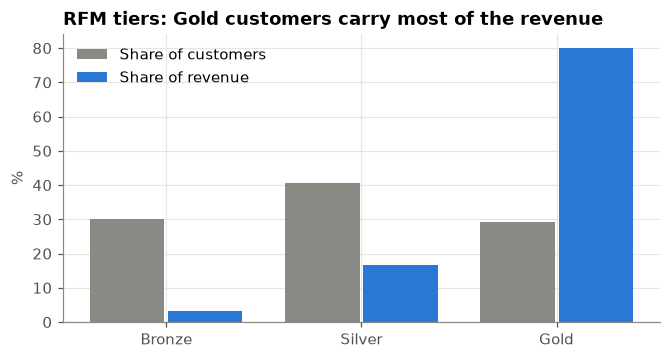

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(tiers))
ax.bar(x - 0.2, tiers.pct_of_customers, width=0.38, color=GREY, label="Share of customers")
ax.bar(x + 0.2, tiers.pct_of_revenue, width=0.38, color=BLUE, label="Share of revenue")
ax.set_xticks(x, tiers.index)
ax.set_ylabel("%")
ax.set_title("RFM tiers: Gold customers carry most of the revenue")
ax.legend()
fig.savefig("../figures/rfm_tiers.png")
plt.show()

## What I expect good segments to look like

Writing this down **before** clustering, as a sanity check for Step 5:

1. A small group of **recent, frequent, high-spending** customers that carries a large share of revenue (the Gold tier suggests about 30% of customers and about 80% of revenue).
2. A large group of **one- or two-time buyers who have not been back for a year or more**: low value, probably lost.
3. Something in between that RFM tiers blur together: customers who **used to buy regularly but are drifting away** (decent F and M, poor R), and **new customers** (good R, low F and M). These need opposite messages, yet a single "Silver" tier mixes them. If K-means separates them, it has earned its place.

In [5]:
rfm.to_csv("../data/processed/rfm.csv")